# UniConnect Marketplace Recommender

This notebook builds and evaluates the recommender for UniConnect's Marketplace.

The question it answers:

> **Given what a student has viewed and added to their cart, which other listings should we show them?**

We compare six approaches, from a dumb baseline to a hybrid model, and measure each one fairly on data it has never seen.

---

**How to use this notebook**

Run the cells from top to bottom (`Run All`). Each section starts with a short explanation of *what* it does and *why*.

The data comes from `python manage.py export_interactions`. Re-export and re-run the notebook any time the data changes.

---

**A note on the data (say this in your report)**

Most of the data is **simulated**. A real recommender needs many users interacting with many items, and a new platform does not have that yet (the "cold start" problem).

So `generate_simulated_data` creates simulated students whose behaviour follows stated, explainable rules (department, level, personal taste, item topic, item appeal). Every simulated row is flagged `is_simulated = 1`.

The point of the evaluation is: *can each model rediscover those patterns from the interactions alone?*

## Step 1: Load the data

We load the three CSV files exported from Django:

- `interactions.csv` is one row per thing a user did (viewed a listing, added it to cart, followed someone...).
- `users.csv` is one row per student, with their department and department *group*.
- `listings.csv` is one row per marketplace listing, with its title, description and category.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

# Works whether Jupyter was started in the project folder or in notebooks/
DATA_DIR = Path('../ml_data') if Path('../ml_data').exists() else Path('ml_data')
FIG_DIR = DATA_DIR.parent / 'notebooks' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

interactions = pd.read_csv(DATA_DIR / 'interactions.csv', parse_dates=['timestamp'])
users = pd.read_csv(DATA_DIR / 'users.csv')
listings = pd.read_csv(DATA_DIR / 'listings.csv')

print(f"{len(interactions):,} interactions, {len(users):,} students, {len(listings):,} listings")
print(f"Simulated share of interactions: {interactions.is_simulated.mean():.1%}")

8,548 interactions, 302 students, 213 listings
Simulated share of interactions: 99.7%


In [2]:
# Chart style: light surface, recessive grid, one blue for single-series charts.
BLUE, GREY = '#2a78d6', '#b9b8b3'
TEXT, MUTED = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#d6d5d0', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': TEXT,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#ecebe7', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

## Step 2: Look at the data before modelling

Two questions matter for choosing a model:

1. **How active is each student?** If most students interact with only a few items, models that rely purely on other users' behaviour (collaborative filtering) will struggle.

2. **How unevenly is attention spread across listings?** If a few items get most of the attention, a "most popular" baseline does well. If attention is spread out, personalisation has more room to help.

In [3]:
# We recommend marketplace listings, so keep listing interactions only,
# and only for listings that still exist.
listing_ix = interactions[(interactions.item_type == 'listing') & interactions.item_id.isin(listings.listing_id)]

print(listing_ix.action.value_counts().to_string())

action
view    4907
cart     544


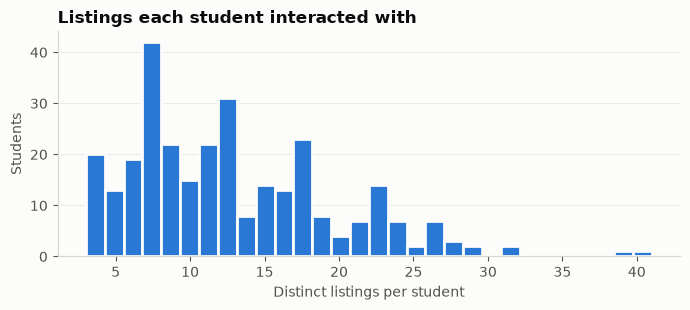

Median: 11 listings per student (out of 213)


In [4]:
per_user = listing_ix.groupby('user_id').item_id.nunique()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_user, bins=30, color=BLUE, edgecolor='#fcfcfb', linewidth=2)
ax.set_title('Listings each student interacted with')
ax.set_xlabel('Distinct listings per student')
ax.set_ylabel('Students')
ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'interactions_per_student.png', dpi=200)
plt.show()

print(f"Median: {per_user.median():.0f} listings per student (out of {len(listings)})")

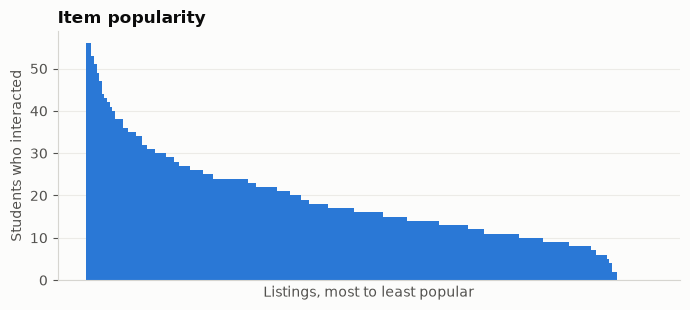

The top 10 listings get 12% of all interactions; 13 listings have none.


In [5]:
popularity = listing_ix.groupby('item_id').user_id.nunique().sort_values(ascending=False)
popularity = popularity.reindex(listings.listing_id).fillna(0).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(popularity)), popularity.values, width=1.0, color=BLUE)
ax.set_title('Item popularity')
ax.set_xlabel('Listings, most to least popular')
ax.set_ylabel('Students who interacted')
ax.set_xticks([])
ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'item_popularity.png', dpi=200)
plt.show()

top10_share = popularity.head(10).sum() / popularity.sum()
print(f"The top 10 listings get {top10_share:.0%} of all interactions; {int((popularity == 0).sum())} listings have none.")

## Step 3: Turn actions into "implicit ratings"

Students never give a star rating. Instead we treat what they *do* as evidence of interest, with stronger actions counting more:

| Action | Weight |
|---|---|
| view | 1 |
| add to cart | 5 |

(These weights are set in `Interaction.ACTION_WEIGHTS`. They are a modelling choice, so justify them in the report.)

A student's rating for a listing is the **sum of the weights** of everything they did with it. Viewing twice and then adding to cart scores 1 + 1 + 5 = 7.

In [6]:
ratings = (listing_ix
           .groupby(['user_id', 'item_id'])
           .agg(rating=('weight', 'sum'), last_seen=('timestamp', 'max'))
           .reset_index())
ratings.head()

,user_id,item_id,rating,last_seen
0,9,40,1.0,2026-09-23 23:50:47.475208+00:00
1,9,71,6.0,2026-09-30 22:10:22.981994+00:00
2,9,132,2.0,2026-10-03 10:12:47.045778+00:00
3,9,163,1.0,2026-08-30 17:50:17.290910+00:00
4,9,164,6.0,2026-09-26 09:18:52.253445+00:00


## Step 4: Split the data fairly (train / validation / test)

A model must be judged on interactions it has **not seen**, otherwise it can simply "remember" the answers.

For every student with at least 5 rated listings, we hide their **most recent 20%**. The model trains on the earlier 80% and must predict the hidden recent ones. That mirrors real use: we learn from the past to predict the future.

We do this twice:

1. **Test set**: the final 20%. Used **once**, at the very end, to report results.
2. **Validation set**: the last 20% of what remains. Used to **tune** the hybrid model.

Tuning on the test set would be cheating, because the results would look better than they really are.

In [7]:
def time_split(df, frac=0.2, min_items=5):
    df = df.sort_values(['user_id', 'last_seen']).copy()
    position = df.groupby('user_id').cumcount()
    n_items = df.groupby('user_id').item_id.transform('size')
    held_out = (n_items >= min_items) & (position >= np.ceil(n_items * (1 - frac)))
    return df[~held_out], df[held_out]

train_full, test = time_split(ratings)   # 80% / 20%
train, val = time_split(train_full)      # split the 80% again for tuning

print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} ratings")
print(f"Students being tested: {test.user_id.nunique()}")

train 2,701 | validation 518 | test 647 ratings
Students being tested: 280


In [8]:
# Index users and items as matrix rows/columns.
item_ids = listings.listing_id.to_numpy()
item_index = {item: i for i, item in enumerate(item_ids)}
user_ids = np.sort(ratings.user_id.unique())
user_index = {user: i for i, user in enumerate(user_ids)}

def rating_matrix(df):
    # Users x items, mostly empty, so it's stored as a sparse matrix.
    return csr_matrix((df.rating, (df.user_id.map(user_index), df.item_id.map(item_index))),
                      shape=(len(user_ids), len(item_ids)))

user_group = users.set_index('user_id').reindex(user_ids)['group'].fillna('general').to_numpy()

M = rating_matrix(train)
print(f"Rating matrix: {M.shape[0]} students x {M.shape[1]} listings, "
      f"{M.nnz / (M.shape[0] * M.shape[1]):.1%} filled")

Rating matrix: 300 students x 213 listings, 4.2% filled


## Step 5: How we measure a recommender

For each test student, a model ranks every listing they haven't interacted with yet and we take its **top 5** (K = 5, roughly what fits in a "Recommended for you" row).

- **Precision@5**: of the 5 recommended, what fraction did the student actually go on to interact with?
- **Recall@5**: of the listings the student went on to interact with, what fraction appeared in the top 5?
- **NDCG@5**: like precision, but a correct item at position 1 counts more than at position 5. *Ranking quality.*
- **Coverage**: what fraction of all listings is ever recommended to anyone? A model that only ever shows the same 10 items is bad for sellers and boring for buyers, even if it is precise.

Absolute numbers look small. With about 3 hidden items among ~200 listings, picking 5 at random hits only about 1% of the time. **What matters is how each model compares to the baselines.**

In [9]:
K = 5

item_titles = listings.set_index('listing_id').title.reindex(item_ids).to_numpy()

def top_k(scores, seen, k=K, one_per_product=False, new_products_only=False):
    # Best k listings by score, never ones already seen.
    #   one_per_product:   several sellers' copies of one product (same title) count once
    #   new_products_only: also skip other sellers' copies of products already seen
    scores = scores.astype(float).copy()
    scores[seen] = -np.inf                       # never re-recommend what they've seen
    picked = []
    titles_used = set(item_titles[seen]) if new_products_only else set()
    one_per_product = one_per_product or new_products_only
    for j in np.argsort(-scores, kind='stable'):
        if not np.isfinite(scores[j]):
            break
        if one_per_product and item_titles[j] in titles_used:
            continue
        picked.append(item_ids[j])
        titles_used.add(item_titles[j])
        if len(picked) == k:
            break
    return picked

def evaluate(model_scores, M, truth_df, k=K, one_per_product=False, new_products_only=False):
    truth = truth_df.groupby('user_id').item_id.apply(set)
    precision = recall = ndcg = 0.0
    ever_recommended = set()
    for user, relevant in truth.items():
        u = user_index[user]
        top = top_k(model_scores(u), M[u].indices, k, one_per_product, new_products_only)
        ever_recommended.update(top)
        hits = [1 if item in relevant else 0 for item in top]
        precision += sum(hits) / k
        recall += sum(hits) / len(relevant)
        dcg = sum(h / np.log2(rank + 2) for rank, h in enumerate(hits))
        ideal = sum(1 / np.log2(rank + 2) for rank in range(min(k, len(relevant))))
        ndcg += dcg / ideal
    n = len(truth)
    return {'precision@5': precision / n, 'recall@5': recall / n,
            'ndcg@5': ndcg / n, 'coverage': len(ever_recommended) / len(item_ids)}

## Step 6: The models

Every model is a function that takes a student and returns **a score for every listing**. Higher means "recommend this first".

### 6a. Random (sanity floor)
Any real model must beat this.

### 6b. Most popular (the baseline to beat)
Recommend whatever is popular overall. Everyone gets the same list.

### 6c. Popular in your department group (demographic)
Recommend what is popular **among students in your department group** (tech, engineering, science, arts, social, law). It uses who you are, not what you did.

### 6d. Item-item collaborative filtering
*"Students who liked this also liked that."* Two listings are similar if the same students interacted with them (cosine similarity between their columns in the rating matrix). A student's score for a listing is how similar it is to everything they've already rated.

### 6e. Content-based (TF-IDF)
Recommend listings whose **text** resembles what you've engaged with. TF-IDF turns each listing's title + description + category into a vector of word weights, where rare, specific words such as "Arduino" or "contract" count more than common ones. Your profile is the weighted average of the vectors of listings you rated.

Unlike collaborative filtering, this can recommend a **brand-new listing nobody has touched yet**.

In [10]:
listing_text = (listings.title + ' ' + listings.description.fillna('') + ' '
                + listings.category + ' ' + listings.condition).to_numpy()
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), sublinear_tf=True)
item_vectors = tfidf.fit_transform(listing_text)
print(f"Each listing is now a vector of {item_vectors.shape[1]:,} word/phrase weights")

def build_models(M, seed=0):
    rng = np.random.default_rng(seed)
    overall_pop = np.asarray(M.sum(axis=0)).ravel()
    group_pop = {g: np.asarray(M[user_group == g].sum(axis=0)).ravel() for g in np.unique(user_group)}
    item_similarity = cosine_similarity(M.T, dense_output=False)

    def random_model(u):
        return rng.random(len(item_ids))

    def popular(u):
        return overall_pop

    def group_popular(u):
        return group_pop[user_group[u]]

    def item_cf(u):
        return (M[u] @ item_similarity).toarray().ravel()

    def content(u):
        if M[u].nnz == 0:
            return np.zeros(len(item_ids))
        profile = normalize(M[u] @ item_vectors)     # weighted average of rated items' vectors
        return (item_vectors @ profile.T).toarray().ravel()

    return {'Random': random_model, 'Most popular': popular, 'Popular in dept group': group_popular,
            'Item-item CF': item_cf, 'Content-based (TF-IDF)': content}

Each listing is now a vector of 931 word/phrase weights


### 6f. Hybrid

Each model above is right about something different, so the hybrid **blends their scores**:

`score = w_cf * CF + w_content * Content + w_group * GroupPopular`

Each model's scores are first rescaled to 0–1 for that student, so no model dominates just because its numbers are bigger.

The weights are not guessed. We try every combination in steps of 0.1 (they sum to 1) and keep the one with the best **NDCG on the validation set**.

In [11]:
def minmax(scores):
    lo, hi = scores.min(), scores.max()
    return (scores - lo) / (hi - lo) if hi > lo else np.zeros_like(scores)

def make_hybrid(models, weights):
    parts = {'cf': models['Item-item CF'], 'content': models['Content-based (TF-IDF)'],
             'group': models['Popular in dept group']}
    return lambda u: sum(w * minmax(parts[name](u)) for name, w in weights.items() if w > 0)

# Tune on train -> validation.
tuning_models = build_models(rating_matrix(train))
M_tune = rating_matrix(train)
results = []
steps = np.round(np.arange(0, 1.01, 0.1), 1)
for w_cf in steps:
    for w_content in steps:
        w_group = round(1 - w_cf - w_content, 1)
        if w_group < 0:
            continue
        weights = {'cf': w_cf, 'content': w_content, 'group': w_group}
        score = evaluate(make_hybrid(tuning_models, weights), M_tune, val)['ndcg@5']
        results.append({**weights, 'val_ndcg@5': score})

tuning = pd.DataFrame(results).sort_values('val_ndcg@5', ascending=False)
best_weights = tuning.iloc[0][['cf', 'content', 'group']].to_dict()
print('Best weights on validation:', best_weights)
tuning.head(5)

Best weights on validation: {'cf': 0.0, 'content': 0.4, 'group': 0.6}


,cf,content,group,val_ndcg@5
4,0.0,0.4,0.6,0.086425
15,0.1,0.4,0.5,0.085303
5,0.0,0.5,0.5,0.083443
24,0.2,0.3,0.5,0.081242
3,0.0,0.3,0.7,0.080445


## Step 7: Final results on the test set

Now each model is trained on the full training data (train + validation) and evaluated **once** on the test set, which nobody has looked at until now.

In [12]:
M_final = rating_matrix(train_full)
final_models = build_models(M_final)
final_models['Hybrid'] = make_hybrid(final_models, best_weights)

results = pd.DataFrame({name: evaluate(fn, M_final, test) for name, fn in final_models.items()}).T
baseline = results.loc['Most popular', 'precision@5']
results['vs. most popular'] = (results['precision@5'] / baseline).map(lambda x: f"{x:.1f}x")
results.round(3)

,precision@5,recall@5,ndcg@5,coverage,vs. most popular
Random,0.012,0.025,0.021,1.000,0.5x
Most popular,0.023,0.057,0.040,0.052,1.0x
Popular in dept group,0.065,0.150,0.116,0.282,2.8x
Item-item CF,0.034,0.065,0.054,0.883,1.5x
Content-based (TF-IDF),0.041,0.081,0.068,0.831,1.8x
Hybrid,0.072,0.158,0.118,0.695,3.2x


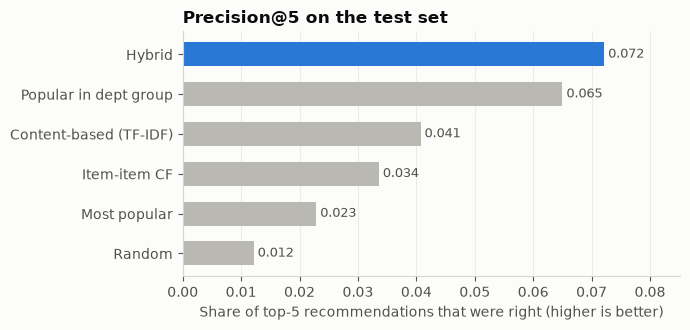

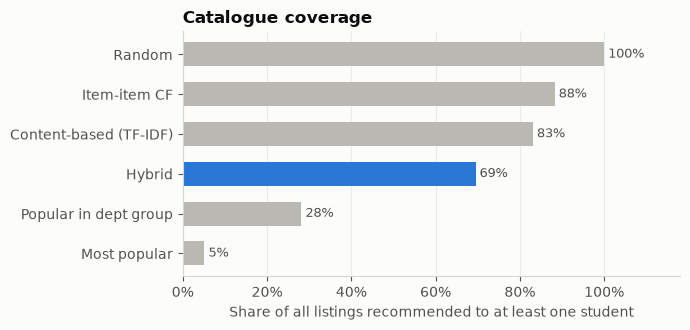

In [13]:
def results_bar(column, title, xlabel, filename, fmt):
    order = results[column].sort_values()
    colors = [BLUE if name == 'Hybrid' else GREY for name in order.index]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    bars = ax.barh(order.index, order.values, color=colors, height=0.6)
    for bar, value in zip(bars, order.values):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, ' ' + fmt(value),
                va='center', color=MUTED, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, order.max() * 1.18)
    if column == 'coverage':
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=200)
    plt.show()

results_bar('precision@5', 'Precision@5 on the test set', 'Share of top-5 recommendations that were right (higher is better)',
            'results_precision.png', lambda v: f'{v:.3f}')
results_bar('coverage', 'Catalogue coverage', 'Share of all listings recommended to at least one student',
            'results_coverage.png', lambda v: f'{v:.0%}')

## Step 7b: Accuracy vs. variety

The catalogue often has **several sellers offering the same product** (e.g. three "Skipping rope" listings). The hybrid sometimes fills the top 5 with copies of one product, which is accurate (students do compare sellers) but repetitive.

Two common fixes, known as **diversity re-ranking**:

- **One listing per product**: never show two copies of the same product in one list.
- **New products only**: also skip other sellers' copies of products the student has already looked at, so every recommendation is something new to them.

The cell below measures what each one costs.

In [14]:
variety = pd.DataFrame({
    'Hybrid (as evaluated)': evaluate(final_models['Hybrid'], M_final, test),
    'Hybrid, one listing per product': evaluate(final_models['Hybrid'], M_final, test, one_per_product=True),
    'Hybrid, new products only': evaluate(final_models['Hybrid'], M_final, test, new_products_only=True),
    'Most popular, new products only': evaluate(final_models['Most popular'], M_final, test, new_products_only=True),
}).T
variety.round(3)

,precision@5,recall@5,ndcg@5,coverage
Hybrid (as evaluated),0.072,0.158,0.118,0.695
"Hybrid, one listing per product",0.048,0.100,0.084,0.695
"Hybrid, new products only",0.032,0.081,0.065,0.357
"Most popular, new products only",0.018,0.046,0.034,0.070


**Reading this:** both fixes cost some precision, because in this data students really do look at several copies of the same item. The fair comparison for "new products only" is the popularity baseline *with the same rule applied*, and the hybrid still beats it.

This is a **product decision**, not a modelling one: higher measured accuracy vs. a more varied list. The app can use either. State which one you chose and why.

## Step 8: What a student actually sees

Numbers are abstract, so here is one simulated student's history and the hybrid's top 5 for them (using the "new products only" rule from Step 7b), each with a one-line reason.

The reason names **whichever signal contributed more** to that item's score:

- If the department-group part was bigger, it says *"popular with law students"*.
- If the student's own history was bigger, it says *"because you viewed X"*, where X is the most similar item they engaged with (matched on title and category).

This is exactly the rule the app uses (`feed/recommender.py`), so the explanations shown to students are honest about why each item appeared.

In [15]:
title_of = listings.set_index('listing_id').title.to_dict()
group_of = dict(zip(users.user_id, users.group))
dept_of = dict(zip(users.user_id, users.department))

def recommend(user, model, M, k=K):
    u = user_index[user]
    return top_k(model(u), M[u].indices, k, new_products_only=True)

GROUP_LABELS = {'tech': 'computing', 'engineering': 'engineering', 'science': 'science',
                'arts': 'arts', 'social': 'social science', 'law': 'law', 'general': 'other'}
# For explanations only: titles + category, so "because you viewed X" names a
# genuinely similar item rather than one sharing stock description phrases.
reason_vectors = TfidfVectorizer(stop_words='english').fit_transform((listings.title + ' ' + listings.category).to_numpy())

def because(user, item, M):
    # Name whichever signal contributed more to this item's blended score.
    u, j = user_index[user], item_index[item]
    group_part = best_weights['group'] * minmax(final_models['Popular in dept group'](u))[j]
    personal_part = (best_weights['content'] * minmax(final_models['Content-based (TF-IDF)'](u))[j]
                     + best_weights['cf'] * minmax(final_models['Item-item CF'](u))[j])
    history = M[u].indices
    if personal_part > group_part and len(history):
        sims = (reason_vectors[history] @ reason_vectors[j].T).toarray().ravel()
        if sims.max() > 0:
            return f'because you viewed "{title_of[item_ids[history[sims.argmax()]]]}"'
    return f'popular with {GROUP_LABELS.get(group_of[user], "other")} students'


# A student with plenty of held-out activity, so the example is informative.
example_user = test.user_id.value_counts().index[0]
history = train_full[train_full.user_id == example_user].sort_values('rating', ascending=False)

print(f"Student {example_user}: {dept_of[example_user]} ({group_of[example_user]} group)\n")
print("Their history (strongest interest first):")
for item, rating in history[['item_id', 'rating']].head(6).itertuples(index=False):
    print(f"  {title_of[item]}  (rating {rating:g})")

print("\nRecommended for them (new products only):")
hidden = set(test[test.user_id == example_user].item_id)
for item in recommend(example_user, final_models['Hybrid'], M_final):
    mark = 'HIT' if item in hidden else '   '
    print(f"  [{mark}] {title_of[item]}  <- {because(example_user, item, M_final)}")

Student 41: Law (law group)

Their history (strongest interest first):
  Skipping rope  (rating 7)
  Used Tecno smartphone  (rating 6)
  Pressing iron  (rating 2)
  Engineering Mathematics by K.A. Stroud  (rating 2)
  Safety boots for workshop  (rating 2)
  Desk organizer  (rating 2)

Recommended for them (new products only):
  [   ] Football (size 5)  <- because you viewed "Football jersey"
  [   ] Law dinner ticket  <- popular with law students
  [   ] Wireless mouse  <- because you viewed "Bluetooth speaker"
  [   ] Mosquito net  <- popular with law students
  [   ] Statistics for Economists textbook  <- because you viewed "Linear Algebra textbook"


## Step 9: Save the chosen settings

The tuned weights are saved so the Django app uses exactly what was evaluated here, not a re-guessed version.

In [16]:
settings_path = DATA_DIR / 'recommender_settings.json'
settings_path.write_text(json.dumps({
    'k': K,
    'weights': {k: float(v) for k, v in best_weights.items()},
    'tfidf': {'stop_words': 'english', 'ngram_range': [1, 2], 'sublinear_tf': True},
    'test_results': results.drop(columns='vs. most popular').round(4).to_dict(orient='index'),
}, indent=2))
print(f"Saved {settings_path}")
print(f"Charts saved in {FIG_DIR}")

Saved ../ml_data/recommender_settings.json
Charts saved in ../notebooks/figures


## Conclusions (draft for your report)

Read the results table above and check these statements still hold for *your* run before using them.

1. **Popularity alone is a weak recommender.** It is better than random but shows nearly everyone the same handful of listings (very low coverage).

2. **Pure collaborative filtering struggles with sparse data.** Each student has interacted with only a few percent of listings, so there is little overlap to learn from. This is the classic weakness of CF on a new platform.

3. **Content-based filtering works without other users' data** and can recommend brand-new listings, but it only finds items similar to what you already looked at.

4. **The hybrid model performs best overall.** It is about 3x as precise as the popularity baseline. Against the strongest single model ("popular in your department group") its precision gain is small, but it recommends a far larger share of the catalogue, so students see more than the same few popular items.

5. **Tuning chose zero weight for collaborative filtering.** On validation data, adding CF did not improve the blend, so the final hybrid is *content + department group*. With so few interactions per student, CF has too little overlap to add anything. It is worth re-tuning once real usage grows.

6. **Accuracy and variety pull against each other.** Showing one listing per product makes the list more useful to look at but lowers measured precision (Step 7b). That is a product choice to justify, not a flaw to hide.

**Limitations to state honestly**

- The data is mostly **simulated**, so results show the models can recover realistic behaviour patterns. They do not prove real-world accuracy. A live A/B test with real students would be the next step.
- The split holds out each student's most recent activity, but other students' activity from the same period stays in training. A stricter global time split would be more conservative.
- Action weights (view = 1, cart = 5) and K = 5 are design choices. Other choices would change the numbers somewhat.